# Проект 1. Как peeking влияет на ложноположительные результаты A/B-теста

## Цель
Показать на симуляции, почему многократная проверка статистической значимости в ходе A/B-теста
увеличивает вероятность ложноположительного результата (FPR), даже если реального эффекта нет,
и сколько стоит корректное решение этой проблемы.

## План исследования
1. Смоделировать множество A/A-тестов: группы имеют одинаковую конверсию.
2. Сравнить проверку только в последний день с проверками каждый день.
3. Ограничить вероятность ложного срабатывания при многократных проверках:
   Pocock, O'Brien–Fleming и Bonferroni.
4. Проверить, что откалиброванные границы работают на **независимой** выборке.
5. Оценить размер выборки и сравнить мощность и скорость остановки методов при небольшом реальном эффекте.
6. Визуализировать результаты и сформулировать практические выводы.

**Ключевая метрика:** FPR (*false positive rate*): доля симуляций, в которых метод ошибочно
обнаружил статистически значимое различие при отсутствии реального эффекта.

**Как запустить:** `pip install -r requirements.txt`, затем `jupyter notebook peeking_simulation.ipynb`.
Все случайные числа зафиксированы через seed, результаты воспроизводимы.

## 1. Параметры эксперимента

Проводим `N_SIM` независимых симуляций. В каждой симуляции ежедневно добавляем новых пользователей
в обе группы и накапливаем число конверсий. В A/A-сценарии конверсия в группах A и B одинакова.

Уровень значимости 5%, число ежедневных проверок равно длительности теста (14 дней).
Для сценария с эффектом (раздел 7) используем рост конверсии с 10% до 12%.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Фиксируем seed для воспроизводимости результатов
rng = np.random.default_rng(42)

# Папка для графиков (используются в README)
IMG = Path("images")
IMG.mkdir(exist_ok=True)

# Параметры эксперимента
N_SIM = 10_000   # количество симуляций
DAYS = 14        # длительность теста и число проверок
DAILY_N = 360    # новых пользователей в день на каждую группу
P = 0.10         # базовая конверсия
P_EFFECT = 0.12  # конверсия группы B в сценарии с реальным эффектом
ALPHA = 0.05     # допустимый уровень ошибки первого рода

# Погрешность оценки доли методом Монте-Карло: FPR = 0.05 на 10 000 симуляций
# неизбежно колеблется примерно на ±0.002, поэтому сравниваем с допуском
MC_SE = np.sqrt(ALPHA * (1 - ALPHA) / N_SIM)
TOL = ALPHA + 2 * MC_SE

## 2. Функции симуляции и расчёта статистики

`simulate()` генерирует накопленные конверсии по дням для двух групп.
`z_stats()` рассчитывает z-статистику для сравнения долей на каждом дне.
Результат: матрица размера `N_SIM × DAYS`.

In [2]:
def simulate(n_sim, days, daily_n, p_a, p_b, rng):
    """Накопленные конверсии A и B и накопленный размер каждой группы."""
    a = rng.binomial(daily_n, p_a, size=(n_sim, days)).cumsum(axis=1)
    b = rng.binomial(daily_n, p_b, size=(n_sim, days)).cumsum(axis=1)
    n = daily_n * np.arange(1, days + 1)
    return a, b, n


def z_stats(a, b, n):
    """Двухвыборочная z-статистика для долей на каждый день."""
    p_a, p_b = a / n, b / n
    pooled = (a + b) / (2 * n)
    se = np.sqrt(pooled * (1 - pooled) * 2 / n)
    return (p_b - p_a) / se

## 3. A/A-симуляция: сценарий без эффекта

Сначала генерируем данные, в которых обе группы имеют одну и ту же конверсию.
Проверка в последний день должна давать FPR около заданных 5%.
Это контрольная проверка корректности симуляции.

In [3]:
a, b, n = simulate(N_SIM, DAYS, DAILY_N, P, P, rng)
z = z_stats(a, b, n)

z_crit = stats.norm.ppf(1 - ALPHA / 2)
fpr_last_day_check = (np.abs(z[:, -1]) > z_crit).mean()

print(f"FPR только в последний день: {fpr_last_day_check:.4f}")
print(f"Ожидаемый уровень alpha:     {ALPHA:.4f} (допуск Монте-Карло ±{2 * MC_SE:.4f})")

FPR только в последний день: 0.0503
Ожидаемый уровень alpha:     0.0500 (допуск Монте-Карло ±0.0044)


## 4. Наивное подглядывание (naive peeking)

Сравниваем два правила:
- **Fixed / final:** принимаем решение только по данным последнего дня.
- **Naive peeking:** проверяем значимость каждый день и объявляем успех, если хотя бы одна проверка
  оказалась значимой.

Во втором случае растёт вероятность хотя бы одного случайного пересечения порога.
Дополнительно рассчитываем накопленный FPR после 1, 2, …, `DAYS` проверок.

In [4]:
def naive_fpr(z, alpha):
    """FPR при проверке только в последний день и при ежедневном peeking."""
    z_crit = stats.norm.ppf(1 - alpha / 2)
    significant = np.abs(z) > z_crit
    fpr_final = significant[:, -1].mean()
    fpr_peeking = significant.any(axis=1).mean()
    return fpr_final, fpr_peeking


def fpr_by_number_of_looks(z, boundary):
    """Накопленный FPR после каждой из последовательных проверок (границы по дням заданы массивом)."""
    hit = np.abs(z) > boundary
    return np.array([hit[:, :k].any(axis=1).mean() for k in range(1, z.shape[1] + 1)])


fpr_final, fpr_peeking = naive_fpr(z, ALPHA)
fpr_curve = fpr_by_number_of_looks(z, np.full(DAYS, z_crit))

print(f"FPR, только последний день: {fpr_final:.4f}")
print(f"FPR, ежедневный peeking:    {fpr_peeking:.4f}")

FPR, только последний день: 0.0503
FPR, ежедневный peeking:    0.2172


## 5. Коррекция на многократные проверки

Калибруем критические границы так, чтобы общая вероятность хотя бы одного ложного срабатывания
за все 14 дней не превышала `ALPHA`.

- **Pocock:** одинаковая граница на каждом дне.
- **O'Brien–Fleming (OBF):** очень строгая граница в начале и почти обычная ближе к концу:
  на дне `k` граница равна `c * sqrt(DAYS / k)`.
- **Bonferroni:** единый порог `alpha / DAYS` на каждой проверке. Консервативен, потому что проверки
  не независимы: данные накапливаются, и z-статистики соседних дней сильно коррелируют.

Для Pocock и OBF подбираем множитель `c` симуляционным перебором, без готовых таблиц.

In [5]:
def calibrate_constant(z, boundary_shape, alpha):
    """Находит минимальный множитель c из сетки, при котором FPR <= alpha."""
    grid = np.linspace(1.5, 4.0, 200)
    for c in grid:
        boundary = c * boundary_shape
        fpr = (np.abs(z) > boundary).any(axis=1).mean()
        if fpr <= alpha:
            return c, fpr

    # Защитный случай: заданного диапазона c не хватило
    c = grid[-1]
    fpr = (np.abs(z) > c * boundary_shape).any(axis=1).mean()
    return c, fpr


days_axis = np.arange(1, DAYS + 1)

shape_pocock = np.ones(DAYS)
shape_obf = np.sqrt(DAYS / days_axis)

c_pocock, fpr_pocock = calibrate_constant(z, shape_pocock, ALPHA)
c_obf, fpr_obf = calibrate_constant(z, shape_obf, ALPHA)

z_bonf = stats.norm.ppf(1 - ALPHA / (2 * DAYS))
fpr_bonf = (np.abs(z) > z_bonf).any(axis=1).mean()

# Границы по дням для каждого метода (используются в проверках, мощности и графиках)
boundaries = {
    "Fixed (только последний день)": np.r_[np.full(DAYS - 1, np.inf), z_crit],
    "Naive peeking": np.full(DAYS, z_crit),
    "Pocock": c_pocock * shape_pocock,
    "O'Brien–Fleming": c_obf * shape_obf,
    "Bonferroni": np.full(DAYS, z_bonf),
}

calibration_results = pd.DataFrame({
    "Метод": list(boundaries.keys()),
    "Порог / параметр": [z_crit, z_crit, c_pocock, c_obf, z_bonf],
    "FPR": [fpr_final, fpr_peeking, fpr_pocock, fpr_obf, fpr_bonf],
})
calibration_results["FPR в пределах допуска"] = calibration_results["FPR"] <= TOL

calibration_results

,Метод,Порог / параметр,FPR,FPR в пределах допуска
0,Fixed (только последний день),1.959964,0.0503,True
1,Naive peeking,1.959964,0.2172,False
2,Pocock,2.618090,0.0491,True
3,O'Brien–Fleming,2.128141,0.0485,True
4,Bonferroni,2.913726,0.0198,True


**Как читать таблицу.** Колонка «Порог / параметр» для Pocock и OBF содержит множитель `c`,
для остальных методов критическое значение z. Колонка допуска сравнивает FPR с `alpha + 2·SE`
(SE ≈ 0.002 из-за конечного числа симуляций), поэтому значение 0.0503 у фиксированного теста считается
нормальным, а 0.217 у naive peeking: нет.

## 6. Проверка на независимой выборке

Множители `c` подобраны на одной и той же выборке, поэтому проверять их на ней же бессмысленно.
Генерируем **новые** A/A-данные с другим seed и смотрим, удерживают ли границы FPR около 5%.
Заодно убеждаемся, что naive peeking по-прежнему даёт сильно завышенный FPR, то есть эффект не случайность
конкретной выборки.

In [6]:
rng_val = np.random.default_rng(2024)
a_v, b_v, n_v = simulate(N_SIM, DAYS, DAILY_N, P, P, rng_val)
z_v = z_stats(a_v, b_v, n_v)

validation = pd.DataFrame({
    "Метод": list(boundaries.keys()),
    "FPR на новой выборке": [(np.abs(z_v) > bnd).any(axis=1).mean() for bnd in boundaries.values()],
})
validation["FPR в пределах допуска"] = validation["FPR на новой выборке"] <= TOL

# Контроль ошибки первого рода удерживают Fixed, Pocock, OBF и Bonferroni
for method in ["Fixed (только последний день)", "Pocock", "O'Brien–Fleming", "Bonferroni"]:
    fpr_v = validation.loc[validation["Метод"] == method, "FPR на новой выборке"].iloc[0]
    assert fpr_v <= TOL, f"{method}: FPR {fpr_v:.4f} выходит за допуск {TOL:.4f}"

# Naive peeking должен сильно превышать alpha и на новой выборке
fpr_naive_v = validation.loc[validation["Метод"] == "Naive peeking", "FPR на новой выборке"].iloc[0]
assert fpr_naive_v > 3 * ALPHA, "Эффект peeking не воспроизвёлся на новой выборке"

print("Все проверки на независимой выборке пройдены.")
validation

Все проверки на независимой выборке пройдены.


,Метод,FPR на новой выборке,FPR в пределах допуска
0,Fixed (только последний день),0.0484,True
1,Naive peeking,0.2186,False
2,Pocock,0.0471,True
3,O'Brien–Fleming,0.0477,True
4,Bonferroni,0.0200,True


## 7. Размер выборки, мощность и скорость остановки при реальном эффекте

**Сначала размер выборки.** Прежде чем сравнивать методы по мощности, нужно убедиться, что сам тест
имеет смысл. Для сравнения долей `p1` и `p2` необходимый размер группы:

`n = (z_{1-α/2} + z_{1-β})² · (p1(1-p1) + p2(1-p2)) / (p2 - p1)²`

Если эффект слишком мал для имеющегося трафика, мощность будет низкой при любом методе.

In [7]:
def required_n_per_group(p1, p2, alpha=0.05, power=0.80):
    """Необходимый размер каждой группы для z-теста двух долей."""
    z_a = stats.norm.ppf(1 - alpha / 2)
    z_b = stats.norm.ppf(power)
    var = p1 * (1 - p1) + p2 * (1 - p2)
    return int(np.ceil((z_a + z_b) ** 2 * var / (p2 - p1) ** 2))


def theoretical_power(p1, p2, n, alpha=0.05):
    """Мощность фиксированного двустороннего z-теста долей при заданном n на группу."""
    z_a = stats.norm.ppf(1 - alpha / 2)
    se = np.sqrt((p1 * (1 - p1) + p2 * (1 - p2)) / n)
    return stats.norm.cdf(abs(p2 - p1) / se - z_a)


n_total = DAILY_N * DAYS
for p2 in (0.11, 0.12):
    print(f"{P:.0%} -> {p2:.0%}: для мощности 80% нужно {required_n_per_group(P, p2):>6,} пользователей на группу; "
          f"при наших {n_total:,} теоретическая мощность fixed-теста = {theoretical_power(P, p2, n_total):.2f}")

10% -> 11%: для мощности 80% нужно 14,749 пользователей на группу; при наших 5,040 теоретическая мощность fixed-теста = 0.37
10% -> 12%: для мощности 80% нужно  3,839 пользователей на группу; при наших 5,040 теоретическая мощность fixed-теста = 0.89


Эффект 10% → 11% при нашем трафике (5 040 на группу) даёт мощность лишь около 37%: тест недоукомплектован,
и сравнение методов на нём малоинформативно. Поэтому используем эффект **10% → 12%**: для него размер выборки близок
к имеющемуся, и мощность fixed-теста около 90%.

**Важно:** данные для сценария с эффектом генерируем **один раз**, и все методы оцениваются на одних и тех же симуляциях.
Так различия между методами не смешиваются с шумом разных случайных выборок.

Для каждого метода считаем:
- **мощность:** доля симуляций, где эффект обнаружен хотя бы в один день;
- **среднее число дней до остановки:** день первого пересечения границы (если границу не пересекли, тест идёт все 14 дней).
  Это главная практическая польза sequential-методов.

In [8]:
a1, b1, n1 = simulate(N_SIM, DAYS, DAILY_N, P, P_EFFECT, rng)
z1 = z_stats(a1, b1, n1)


def evaluate(z_eff, boundary):
    """Мощность и среднее число дней до остановки для заданных границ по дням."""
    hit = np.abs(z_eff) > boundary
    detected = hit.any(axis=1)
    stop_day = np.where(detected, hit.argmax(axis=1) + 1, DAYS)
    return detected.mean(), stop_day.mean()


rows = []
for method, bnd in boundaries.items():
    power_m, mean_stop = evaluate(z1, bnd)
    rows.append((method, power_m, mean_stop))

power_results = pd.DataFrame(rows, columns=["Метод", "Мощность", "Среднее число дней до остановки"])
power_results["FPR без эффекта"] = calibration_results["FPR"].values

power_results.round(4)

,Метод,Мощность,Среднее число дней до остановки,FPR без эффекта
0,Fixed (только последний день),0.8909,14.0000,0.0503
1,Naive peeking,0.9326,5.7156,0.2172
2,Pocock,0.7894,8.5381,0.0491
3,O'Brien–Fleming,0.8757,9.8537,0.0485
4,Bonferroni,0.6904,9.7849,0.0198


**Как читать.** Naive peeking формально имеет самую высокую мощность, но платит за неё FPR около 22%:
сравнивать его мощность с остальными методами нельзя. Среди методов с честным контролем ошибки
Pocock и OBF находят эффект раньше, чем fixed-тест (меньше среднее число дней), при этом OBF
теряет меньше мощности, чем Pocock и тем более Bonferroni.

## 8. Визуализация результатов

**График 1.** Как накапливается вероятность ложного срабатывания по мере увеличения числа проверок:
naive peeking растёт, откалиброванные границы остаются около уровня alpha.

**График 2.** Траектории z-статистики в 20 A/A-симуляциях. Красным выделены траектории, которые хотя бы раз
вышли за обычную границу ±1.96: при ежедневном peeking каждая из них была бы объявлена «успешным» тестом,
хотя эффекта нет. Границы Pocock и OBF пропускают такие
случайные выбросы лишь в ~5% случаев (одна из 20 траекторий на графике всё же их пересекает: это ожидаемо).

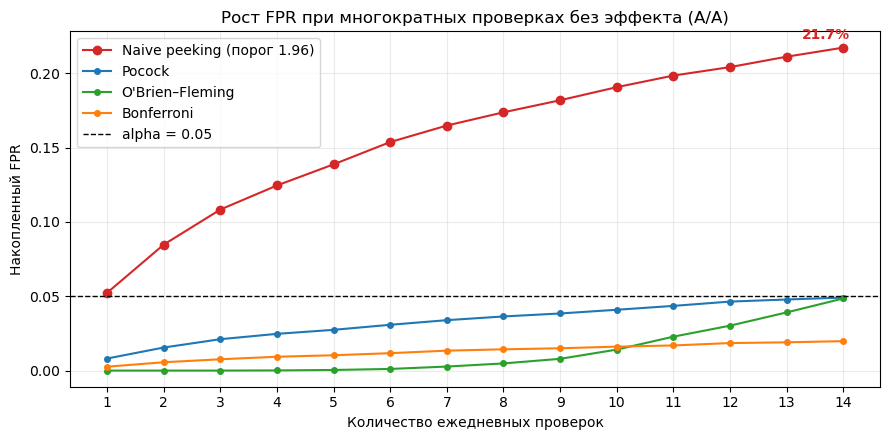

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(days_axis, fpr_curve, marker="o", color="C3", label="Naive peeking (порог 1.96)")
for method, color in [("Pocock", "C0"), ("O'Brien–Fleming", "C2"), ("Bonferroni", "C1")]:
    curve = fpr_by_number_of_looks(z, boundaries[method])
    ax.plot(days_axis, curve, marker="o", markersize=4, color=color, label=method)
ax.axhline(ALPHA, color="black", linestyle="--", linewidth=1, label=f"alpha = {ALPHA:.2f}")
ax.annotate(f"{fpr_curve[-1]:.1%}", (DAYS, fpr_curve[-1]), textcoords="offset points",
            xytext=(-30, 6), color="C3", fontweight="bold")
ax.set(
    xlabel="Количество ежедневных проверок",
    ylabel="Накопленный FPR",
    title="Рост FPR при многократных проверках без эффекта (A/A)"
)
ax.set_xticks(days_axis)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
fig.savefig(IMG / "fpr_growth.png", dpi=150)
plt.show()

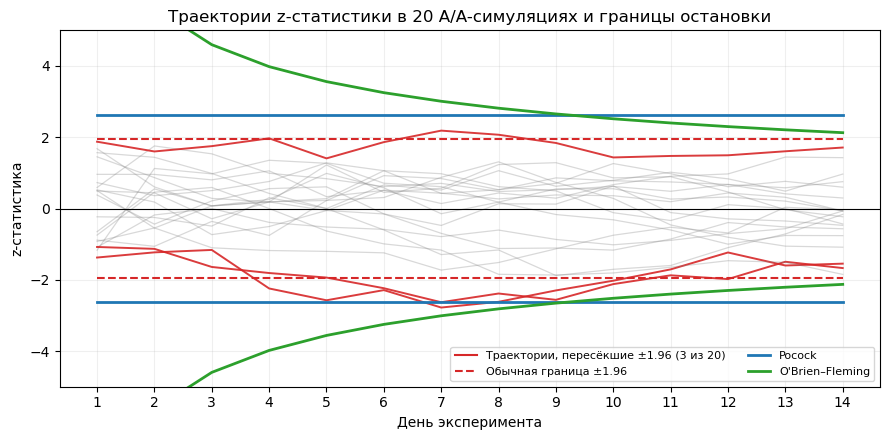

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
crossed = (np.abs(z[:20]) > z_crit).any(axis=1)   # какие из 20 траекторий хоть раз пересекли ±1.96
for i in range(20):
    ax.plot(days_axis, z[i], alpha=0.9 if crossed[i] else 0.3, linewidth=1.4 if crossed[i] else 0.9,
            color="C3" if crossed[i] else "gray")
ax.plot([], [], color="C3", label=f"Траектории, пересёкшие ±1.96 ({crossed.sum()} из 20)")

ax.axhline(0, color="black", linewidth=0.8)
for sign in (1, -1):
    ax.plot(days_axis, sign * boundaries["Naive peeking"], color="C3", linestyle="--",
            label="Обычная граница ±1.96" if sign == 1 else None)
    ax.plot(days_axis, sign * boundaries["Pocock"], color="C0", linewidth=2,
            label="Pocock" if sign == 1 else None)
    ax.plot(days_axis, sign * boundaries["O'Brien–Fleming"], color="C2", linewidth=2,
            label="O'Brien–Fleming" if sign == 1 else None)

ax.set(
    xlabel="День эксперимента",
    ylabel="z-статистика",
    title="Траектории z-статистики в 20 A/A-симуляциях и границы остановки",
    ylim=(-5, 5)
)
ax.set_xticks(days_axis)
ax.grid(alpha=0.2)
ax.legend(loc="lower right", ncol=2, fontsize=8)
plt.tight_layout()
fig.savefig(IMG / "z_trajectories.png", dpi=150)
plt.show()

## 9. Итог и практические выводы

### Что показала симуляция (10 000 A/A-тестов, 14 дней, 5 040 пользователей на группу, α = 5%)

| Правило остановки | FPR без эффекта | Мощность при 10% → 12% | Среднее число дней до остановки |
|---|---|---|---|
| Fixed (решение только в день 14) | ≈ 5.0% | ≈ 89% | 14.0 |
| Naive peeking (порог 1.96 каждый день) | **≈ 21.7%** | ≈ 93% (нечестная, FPR завышен) | ≈ 5.7 |
| Pocock (c ≈ 2.62) | ≈ 4.9% | ≈ 79% | ≈ 8.5 |
| O'Brien–Fleming (c ≈ 2.13) | ≈ 4.9% | ≈ 88% | ≈ 9.9 |
| Bonferroni (z ≈ 2.91) | ≈ 2.0% | ≈ 69% | ≈ 9.8 |

1. **Peeking ломает тест.** Если ежедневно смотреть на обычный p-value и останавливаться при первой «значимости»,
   вероятность ложного вывода растёт с 5% до ≈ 22%, то есть примерно каждый пятый тест без эффекта объявляется успешным.
   Результат воспроизвёлся на независимой выборке (≈ 22%).
2. **Контроль ошибки возвращается корректными границами.** Pocock и OBF, откалиброванные симуляцией,
   удерживают FPR около 5% и на новой выборке.
3. **Контроль стоит мощности, но цена разная.** OBF почти не теряет мощность относительно fixed-теста (≈ 88% против ≈ 89%)
   и при этом в среднем останавливает тест на ≈ 4 дня раньше. Pocock теряет ≈ 10 п.п. мощности,
   Bonferroni ≈ 20 п.п. из-за консервативности: он не учитывает, что проверки зависимы.
4. **Высокая мощность naive peeking иллюзорна:** она достигается ценой недопустимого уровня ложных срабатываний.

### Практические правила для команды
- До старта фиксировать метрику, MDE, уровень значимости, мощность, размер выборки и длительность
  (по возможности кратную целым неделям из-за недельной сезонности).
- Не останавливать тест по p-value раньше срока. Если требуется ранняя остановка по бизнес-причинам,
  заранее заложить sequential-дизайн (например, границы типа O'Brien–Fleming или alpha spending).
- Если эффект слишком мал для трафика, сначала решать вопрос выборки: никакой метод остановки не заменит мощность.

### Ограничения исследования
- Моделируется сравнение двух долей z-тестом с равномерным притоком пользователей и 14 равноотстоящими проверками;
  реальные метрики (средние, ratio-метрики, неравномерный трафик, недельная сезонность) требуют отдельного анализа.
- Границы Pocock и OBF откалиброваны под ровно 14 равноотстоящих проверок; при другом расписании константы нужно пересчитать.
- Оценки получены методом Монте-Карло и имеют погрешность порядка ±0.2 п.п. для FPR около 5%.
- Эффект рассмотрен один (10% → 12%); для полной картины стоит построить кривую мощности по нескольким размерам эффекта.
